# 02 · Clasificación de indicadores en dimensiones teóricas (LLM)

**Objetivo.** Evaluar la clasificación automática de indicadores en las cuatro dimensiones del marco teórico (monetaria, institucional, estructural, sociodemográfica) y documentar cómo se construye el universo final de variables.

**Diseño.**
- Modelo: `openai/gpt-oss-120b` vía Groq, de pesos abiertos y versión fija; temperatura 0, semilla 42, respuestas crudas en caché.
- Selección del codebook: tres versiones (V0, V1, V2) evaluadas contra 100 indicadores clasificados a mano por la autora.
- Clasificación del universo: dos corridas independientes con el codebook V2. Los indicadores sin acuerdo entre corridas se resolvieron por revisión (`metodo = "clasificacion manual"`, `revisor` documentado).
- Reglas posteriores: variables protegidas por teoría, exclusión de niveles absolutos no comparables, de medidas de precios y de casos ambiguos.

Scripts: `pipeline/classify_sample.py`, `pipeline/classify_universe.py`, `pipeline/consolidate_classification.py`.

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from inflacion.config import Paths, load_params
from inflacion.viz import CATEGORICAL, CLUSTER_COLORS, DIM_LABELS, DIMENSION_COLORS, apply_theme, heatmap, show, subtitle
from inflacion.viz.theme import DIVERGING, INK_MUTED, INK_SECONDARY, SEQUENTIAL_BLUE

apply_theme()
P = load_params()
D = Paths.processed
pd.set_option("display.precision", 3)
CL = D / "classification"
metrics = pd.read_csv(CL / "muestra100_metricas.csv")
pred = pd.read_csv(CL / "muestra100_predicciones.csv")
final = pd.read_csv(CL / "clasificacion_final.csv")
DIMS = ["MONETARIA", "SOCIODEMOGRAFICA", "INSTITUCIONAL", "ESTRUCTURAL"]
print(pred["clasificacion_humana"].value_counts())

clasificacion_humana
SOCIODEMOGRAFICA    38
INSTITUCIONAL       36
ESTRUCTURAL         17
MONETARIA            9
Name: count, dtype: int64


## 1. Selección del codebook

Las métricas se calculan sobre los 100 indicadores y, aparte, sobre los 89 que no aparecen citados como ejemplo en ningún codebook. Los indicadores citados favorecen artificialmente a la versión que los menciona, porque el modelo ya vio su respuesta en el propio codebook.

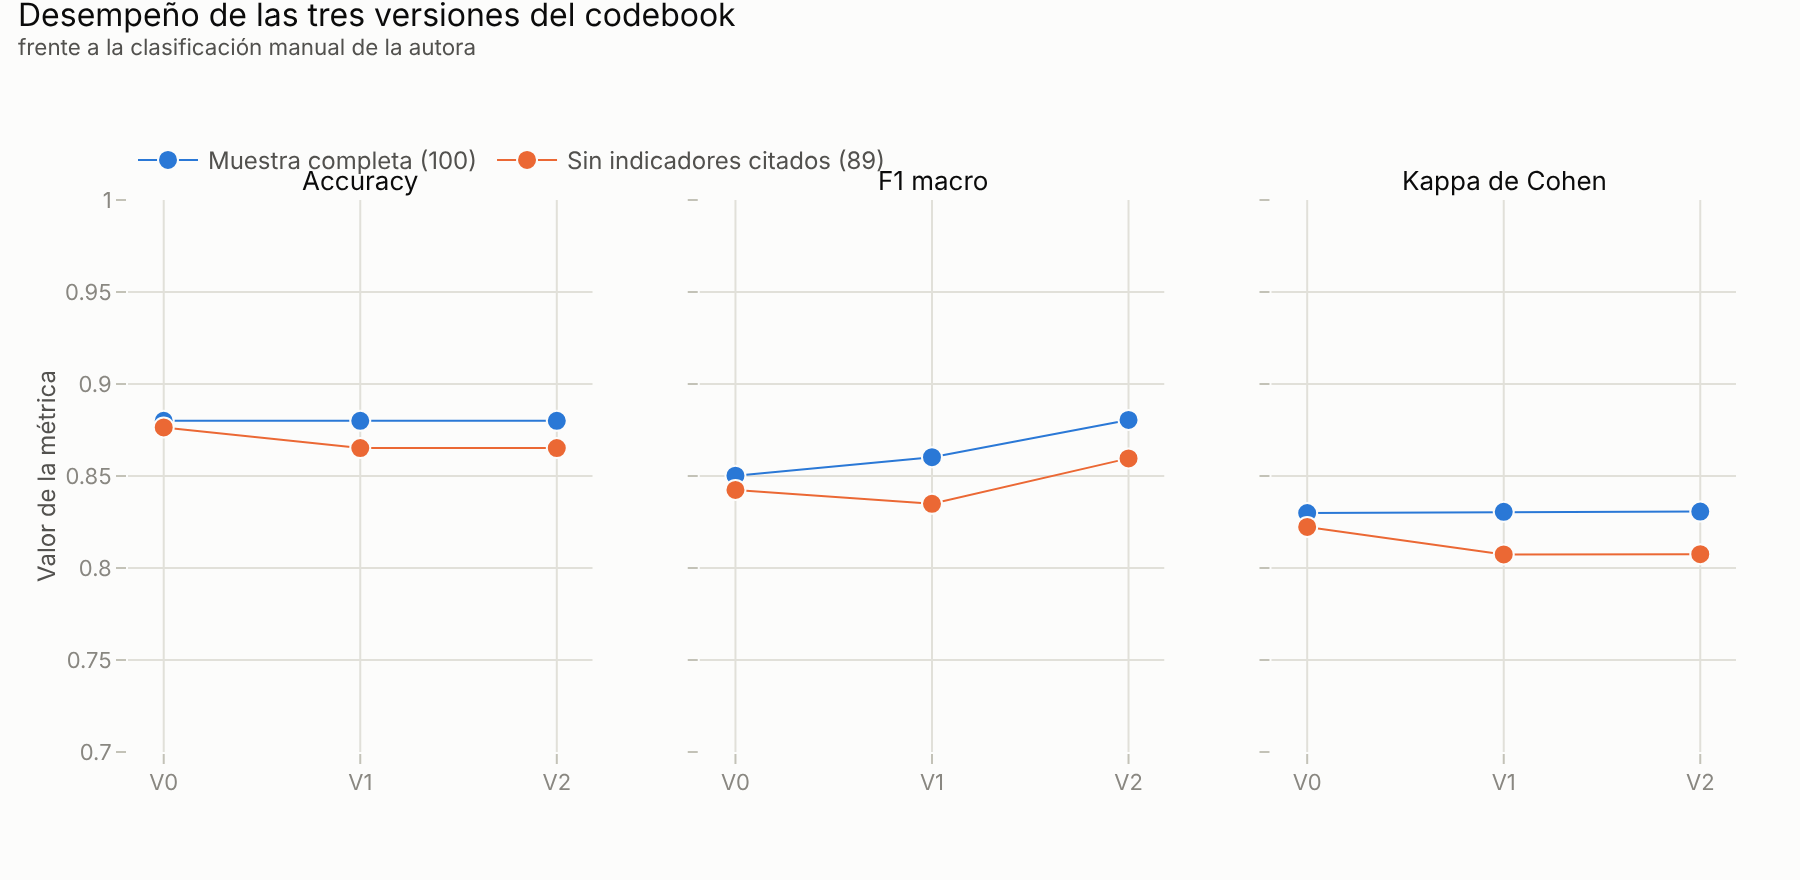

,codebook,subconjunto,n,accuracy,macro_f1,kappa,cobertura,accuracy_decididos
0,v0,100,100,0.880,0.850,0.830,0.960,0.917
1,v0,89_sin_citados,89,0.876,0.842,0.822,0.966,0.907
2,v1,100,100,0.880,0.860,0.831,0.980,0.898
3,v1,89_sin_citados,89,0.865,0.835,0.807,0.978,0.885
4,v2,100,100,0.880,0.880,0.831,0.970,0.907
5,v2,89_sin_citados,89,0.865,0.860,0.807,0.966,0.895


In [2]:
m = metrics.copy()
m["sub"] = np.where(m["subconjunto"] == "100", "Muestra completa (100)", "Sin indicadores citados (89)")
fig = make_subplots(rows=1, cols=3, subplot_titles=("Accuracy", "F1 macro", "Kappa de Cohen"), shared_yaxes=True)
for col, met in enumerate(["accuracy", "macro_f1", "kappa"], start=1):
    for i, (sub, g) in enumerate(m.groupby("sub", sort=False)):
        fig.add_scatter(x=g["codebook"].str.upper(), y=g[met], mode="markers+lines", name=sub, legendgroup=sub,
                        showlegend=col == 1, marker=dict(size=10, color=CATEGORICAL[i]), line=dict(width=1, color=CATEGORICAL[i]),
                        hovertemplate=sub + " · %{x}: %{y:.3f}<extra></extra>", row=1, col=col)
fig.update_yaxes(range=[0.7, 1.0], row=1, col=1, title_text="Valor de la métrica")
fig.update_annotations(font_size=13)
fig.update_layout(title=subtitle("Desempeño de las tres versiones del codebook", "frente a la clasificación manual de la autora"))
show(fig, "02_codebooks_metricas", height=440)
metrics.round(3)

In [3]:
from statsmodels.stats.contingency_tables import mcnemar
for a, b in [("v0", "v2"), ("v1", "v2"), ("v0", "v1")]:
    ok_a, ok_b = pred[f"llm_{a}"] == pred["clasificacion_humana"], pred[f"llm_{b}"] == pred["clasificacion_humana"]
    t = pd.crosstab(ok_a, ok_b).reindex(index=[True, False], columns=[True, False], fill_value=0)
    print(f"McNemar {a.upper()} vs {b.upper()}: discordantes {t.loc[True, False]}/{t.loc[False, True]} · p = {mcnemar(t, exact=True).pvalue:.3f}")
print(f"Acuerdo V2 consigo mismo (dos corridas): {(pred['llm_v2'] == pred['llm_v2_rep']).mean():.0%}")

McNemar V0 vs V2: discordantes 4/4 · p = 1.000
McNemar V1 vs V2: discordantes 3/3 · p = 1.000
McNemar V0 vs V1: discordantes 4/4 · p = 1.000
Acuerdo V2 consigo mismo (dos corridas): 96%


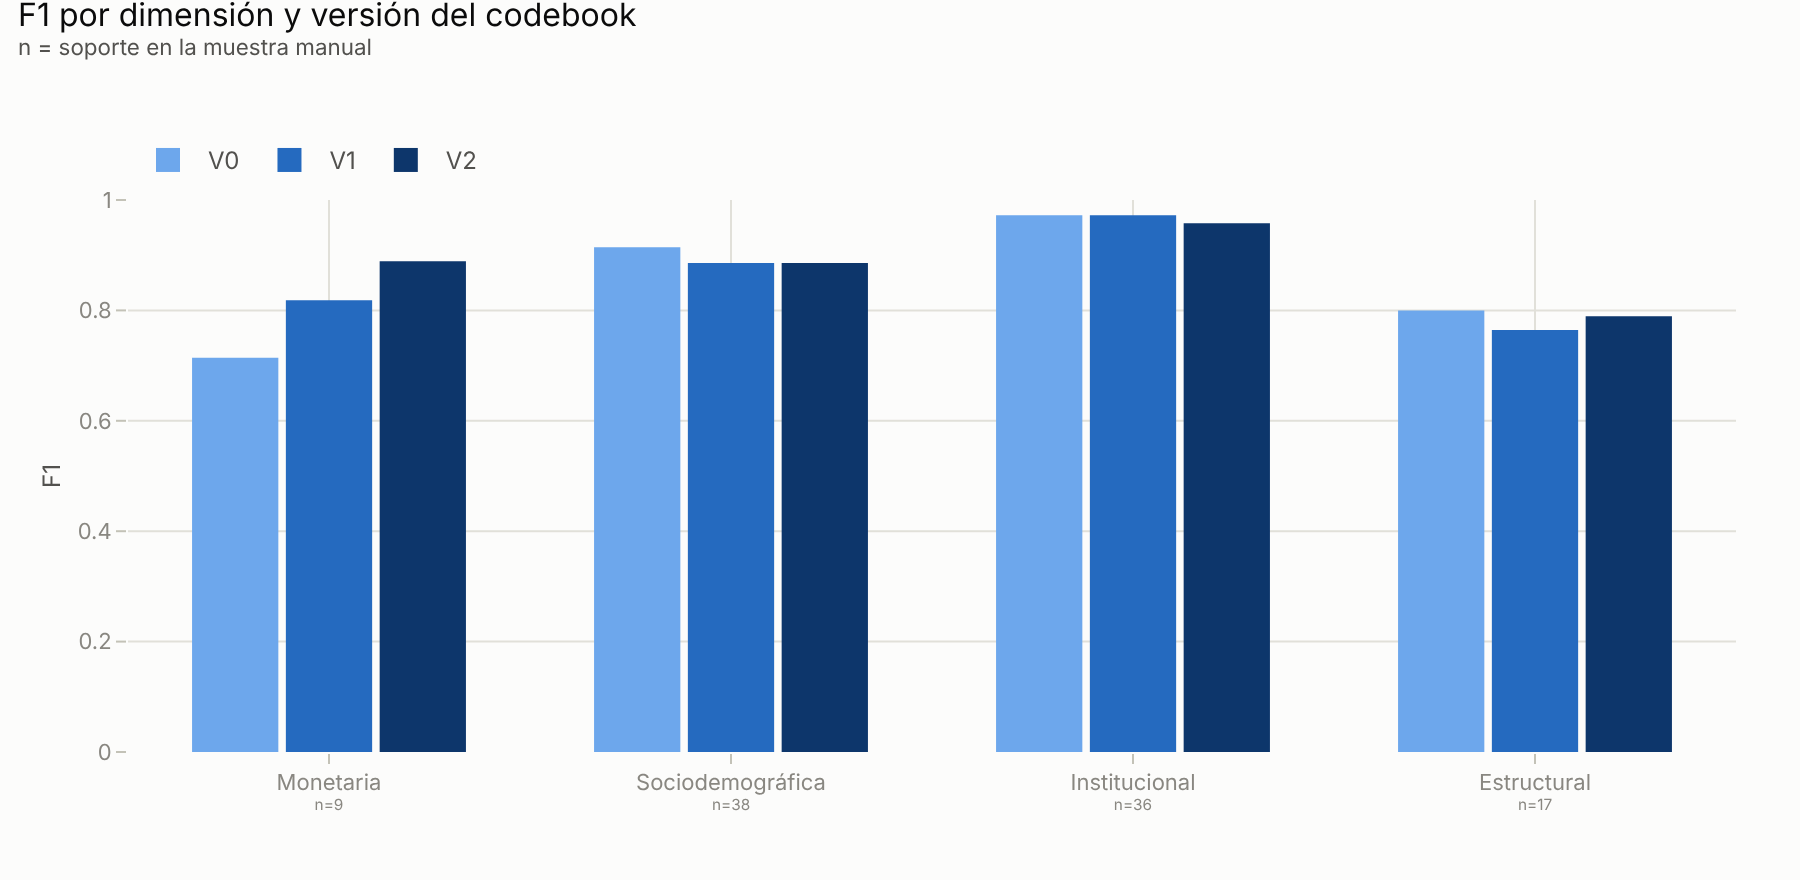

In [4]:
y = pred["clasificacion_humana"]
pc = []
for v in ["v0", "v1", "v2"]:
    for d in DIMS:
        tp = ((pred[f"llm_{v}"] == d) & (y == d)).sum()
        prec, rec = tp / max((pred[f"llm_{v}"] == d).sum(), 1), tp / (y == d).sum()
        pc.append({"codebook": v.upper(), "dimension": d, "f1": 2 * prec * rec / (prec + rec) if prec + rec else 0, "soporte": int((y == d).sum())})
pc = pd.DataFrame(pc)
fig = go.Figure()
for i, v in enumerate(["V0", "V1", "V2"]):
    g = pc[pc["codebook"] == v]
    fig.add_bar(x=[f"{DIM_LABELS[d]}<br><sup>n={n}</sup>" for d, n in zip(g["dimension"], g["soporte"])], y=g["f1"], name=v,
                marker_color=SEQUENTIAL_BLUE[2 + 2 * i], hovertemplate=v + " · %{x}: F1 %{y:.2f}<extra></extra>")
fig.update_layout(barmode="group", bargap=0.3, bargroupgap=0.08, yaxis=dict(title="F1", range=[0, 1]),
                  title=subtitle("F1 por dimensión y versión del codebook", "n = soporte en la muestra manual"))
show(fig, "02_f1_por_dimension", height=440)

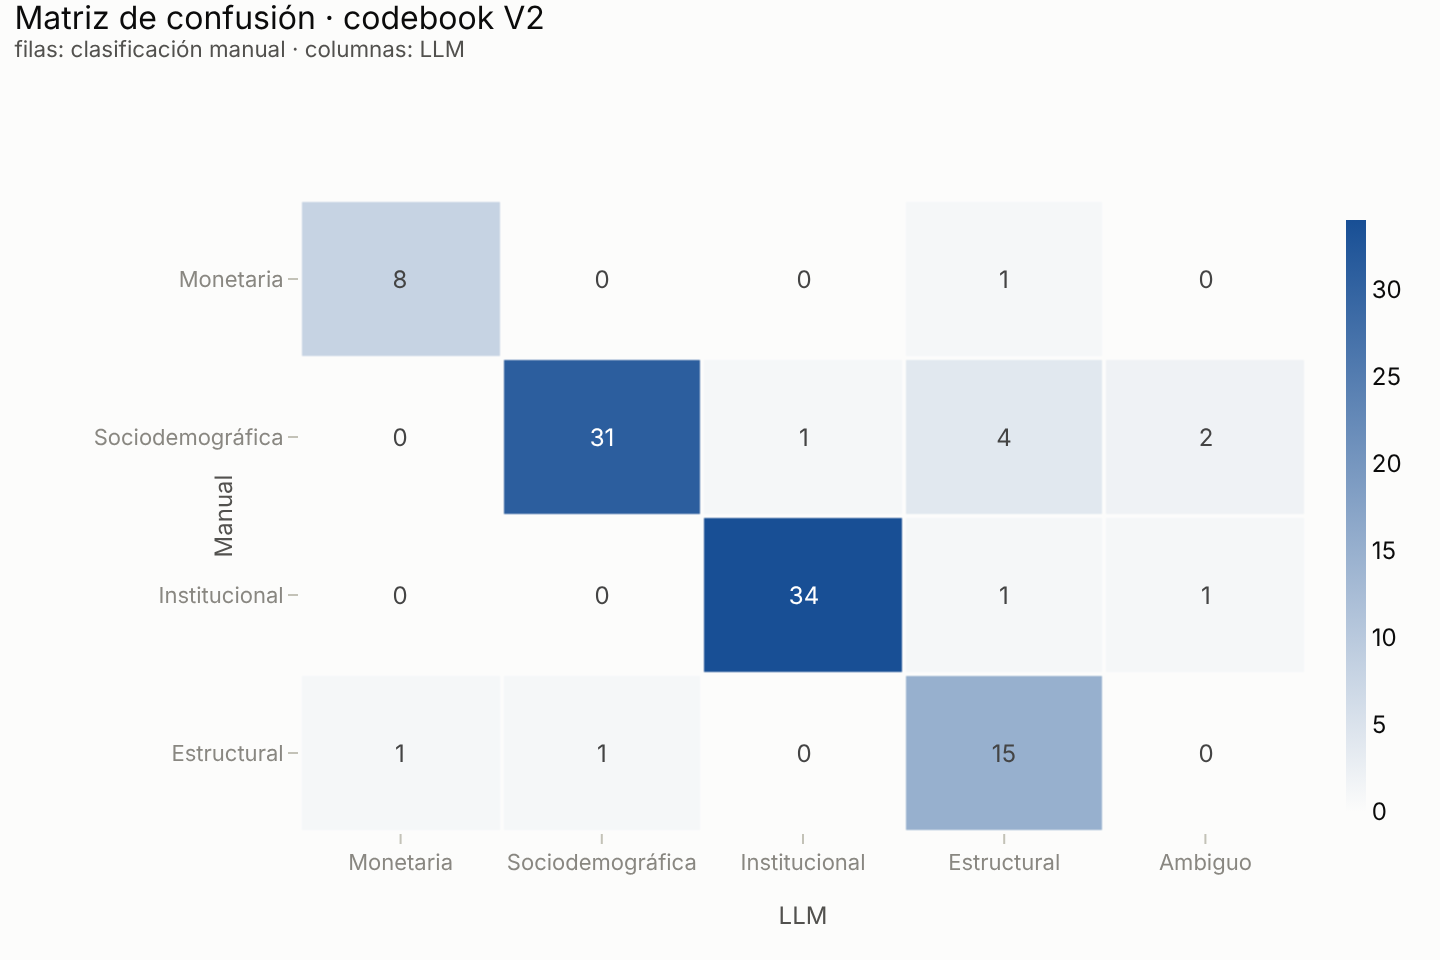

In [5]:
from inflacion.classification.evaluation import confusion
cm = confusion(y, pred["llm_v2"])
cm.index = [DIM_LABELS.get(i, i.capitalize()) for i in cm.index]
cm.columns = [DIM_LABELS.get(i, i.capitalize()) for i in cm.columns]
cm = cm.drop(index="Ambiguo")
fig = heatmap(cm, subtitle("Matriz de confusión · codebook V2", "filas: clasificación manual · columnas: LLM"),
              colorscale=[[0, "#fcfcfb"], [1, SEQUENTIAL_BLUE[5]]], fmt="d")
fig.update_layout(xaxis_title="LLM", yaxis_title="Manual")
show(fig, "02_confusion_v2", width=720, height=480)

**Interpretación.** Las tres versiones alcanzan la misma accuracy (0,88) y kappa (0,83) sobre la muestra completa. Sobre los 89 indicadores no citados, todas caen apenas (0,865-0,876). Con 100 casos, cada indicador vale un punto porcentual, y en la evaluación previa la prueba de McNemar entre versiones dio p = 1,0: **las versiones no se distinguen estadísticamente**. La mejora visible está en la dimensión monetaria: V0 omite 4 de 9 indicadores monetarios porque todavía no incluía las variables fiscales en sentido amplio, y V1/V2 sí. Con solo 9 casos, de todos modos, es una diferencia frágil.

Se elige **V2** por ser la versión con reglas más completas y documentadas, no porque rinda más. La matriz de confusión muestra que el error dominante es sociodemográfica → estructural (4 casos): indicadores de empleo que son a la vez característica del agente y estructura ocupacional, un límite del propio codebook más que del modelo.

## 2. Estabilidad entre corridas sobre el universo

Con temperatura 0 el modelo no es del todo determinista. Clasificar el universo dos veces permite separar las asignaciones estables de las que dependen de la ejecución.

Acuerdo entre corridas (%): {'V-Dem': 97.5, 'WDI': 89.3}


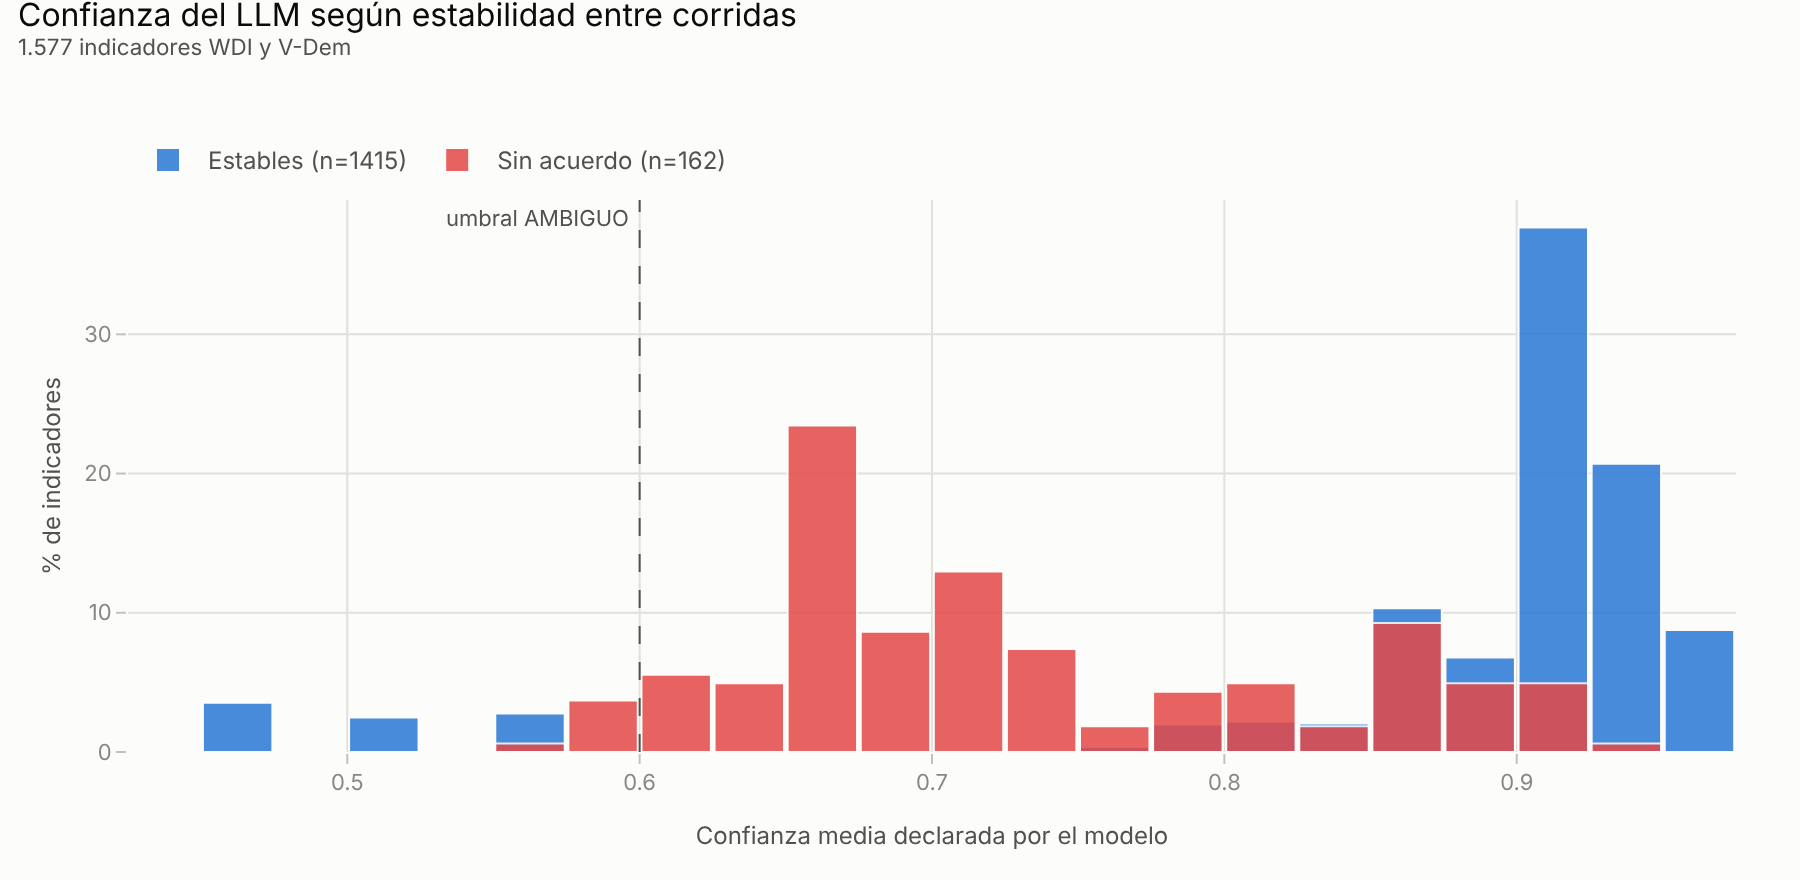

estable
False    0.70
True     0.92
Name: confianza_media, dtype: float64


In [6]:
wdi_vd = final[final["fuente"].isin(["WDI", "V-Dem"])].copy()
agree = wdi_vd.groupby("fuente")["estable"].mean().mul(100).round(1)
print("Acuerdo entre corridas (%):", agree.to_dict())
fig = go.Figure()
for i, (lab, g) in enumerate([("Estables", wdi_vd[wdi_vd["estable"]]), ("Sin acuerdo", wdi_vd[~wdi_vd["estable"]])]):
    fig.add_histogram(x=g["confianza_media"], name=f"{lab} (n={len(g)})", histnorm="percent", opacity=0.85,
                      xbins=dict(start=0.3, end=1.0001, size=0.025), marker_color=CATEGORICAL[i * 7])
fig.add_vline(x=0.60, line=dict(color=INK_SECONDARY, dash="dash", width=1))
fig.add_annotation(x=0.60, y=1, yref="paper", text="umbral AMBIGUO", showarrow=False, xanchor="right", xshift=-4,
                   font=dict(size=11, color=INK_SECONDARY))
fig.update_layout(barmode="overlay", bargap=0.05, xaxis_title="Confianza media declarada por el modelo",
                  yaxis_title="% de indicadores", title=subtitle("Confianza del LLM según estabilidad entre corridas",
                                                                 "1.577 indicadores WDI y V-Dem"))
show(fig, "02_confianza_estabilidad", height=440)
print(wdi_vd.groupby("estable")["confianza_media"].median().round(2))

**Interpretación.** Las dos corridas coinciden en el 89,3% de los indicadores WDI y en el 97,5% de V-Dem. La inestabilidad no es aleatoria: se concentra en los casos que el propio modelo declara dudosos (confianza mediana 0,70 en los inestables vs. 0,92 en los estables), muchos de ellos alrededor del umbral de 0,60 que separa una dimensión de AMBIGUO. Repetir la clasificación funciona así como un detector de casos frontera: los 162 indicadores sin acuerdo se resolvieron uno a uno, citando la regla del codebook aplicada (ver `src/inflacion/classification/review_decisions.py`).

## 3. Del catálogo al universo de análisis

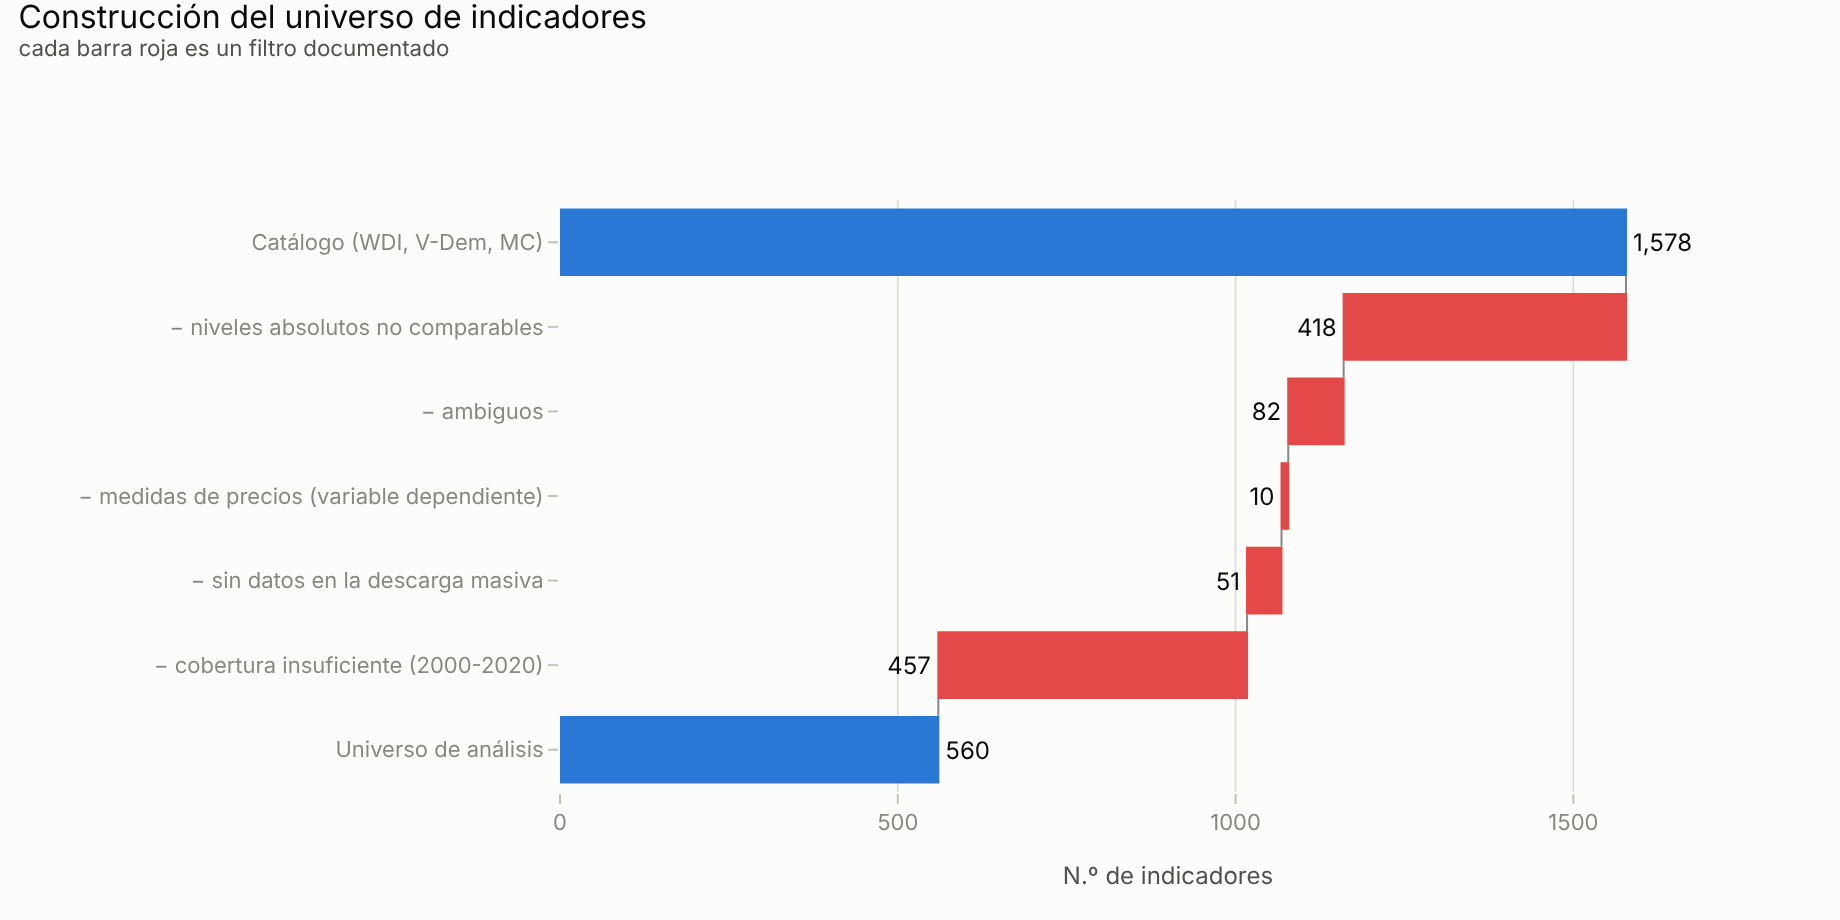

In [7]:
cov = pd.read_csv(D / "cobertura_indicadores.csv")
steps = [
    ("Catálogo (WDI, V-Dem, MC)", len(final)),
    ("− niveles absolutos no comparables", -int((final["motivo_exclusion"] == "nivel_absoluto_no_comparable").sum())),
    ("− ambiguos", -int((final["motivo_exclusion"] == "ambiguo").sum())),
    ("− medidas de precios (variable dependiente)", -int((final["motivo_exclusion"] == "medida_de_precios").sum())),
    ("− sin datos en la descarga masiva", -(int(final["incluir"].sum()) - int((cov["dimension"] != "TARGET").sum()))),
    ("− cobertura insuficiente (2000-2020)", -int(((cov["dimension"] != "TARGET") & ~cov["cumple_umbral"]).sum())),
]
labels = [s for s, _ in steps] + ["Universo de análisis"]
vals = [v for _, v in steps]
fig = go.Figure(go.Waterfall(orientation="h", y=labels, x=vals + [None], measure=["absolute"] + ["relative"] * (len(vals) - 1) + ["total"],
                             text=[f"{abs(v):,}" for v in vals] + [f"{sum(vals):,}"], textposition="outside",
                             connector=dict(line=dict(color=INK_MUTED, width=1)),
                             decreasing=dict(marker=dict(color=CATEGORICAL[7])), increasing=dict(marker=dict(color=CATEGORICAL[0])),
                             totals=dict(marker=dict(color=CATEGORICAL[0]))))
fig.update_layout(title=subtitle("Construcción del universo de indicadores", "cada barra roja es un filtro documentado"),
                  yaxis=dict(autorange="reversed", showgrid=False), xaxis=dict(title="N.º de indicadores", range=[0, 1800]),
                  showlegend=False, margin=dict(l=280))
show(fig, "02_flujo_indicadores", width=920, height=460)

**Interpretación.** El filtro más importante no es el del LLM sino el de **comparabilidad** (418 indicadores): totales en moneda local o en US$ y conteos absolutos que escalan con el tamaño del país (población por edad, matrícula, suscripciones, refugiados). La regla se aplica por patrones sobre el nombre y el código del indicador, y se auditó listando los indicadores incluidos sin unidad relativa explícita. En un PCA, esas variables harían que el primer componente midiera tamaño de economía en lugar de perfil. Las 10 medidas de precios (IPC, deflactores, índices de precios mayoristas y de nivel de precios) se excluyen porque son el fenómeno a explicar: dejarlas como predictores introduciría circularidad. Finalmente, la cobertura temporal elimina 457 indicadores, sobre todo series de encuestas esporádicas.

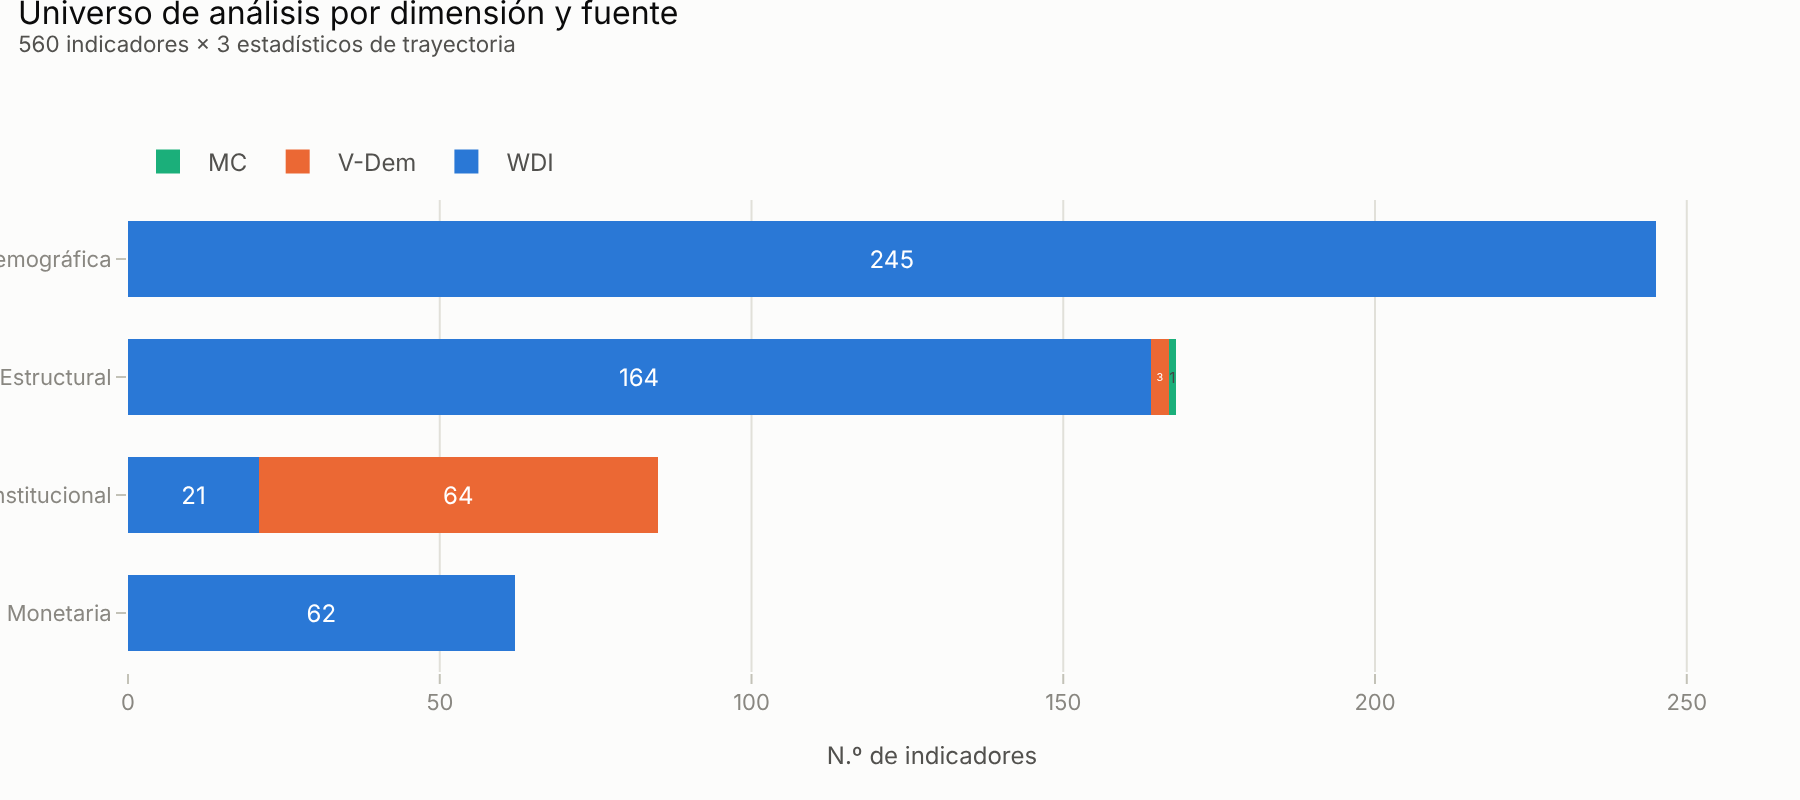

fuente,MC,V-Dem,WDI,total
dimension,,,,
ESTRUCTURAL,1,3,164,168
INSTITUCIONAL,0,64,21,85
MONETARIA,0,0,62,62
SOCIODEMOGRAFICA,0,0,245,245


In [8]:
incl = cov[cov["cumple_umbral"] & (cov["dimension"] != "TARGET")]
tab = incl.groupby(["dimension", "fuente"]).size().unstack(fill_value=0)
fig = go.Figure()
for i, src in enumerate(["WDI", "V-Dem", "MC"]):
    if src in tab:
        fig.add_bar(y=[DIM_LABELS[d] for d in tab.index], x=tab[src], name=src, orientation="h", marker_color=CATEGORICAL[i],
                    text=tab[src].where(tab[src] > 0, ""), textposition="inside", insidetextanchor="middle",
                    hovertemplate=src + " · %{y}: %{x}<extra></extra>")
fig.update_layout(barmode="stack", bargap=0.35, xaxis_title="N.º de indicadores",
                  title=subtitle("Universo de análisis por dimensión y fuente", f"{len(incl)} indicadores × 3 estadísticos de trayectoria"),
                  yaxis=dict(categoryorder="total ascending", showgrid=False))
show(fig, "02_universo_por_dimension", height=400)
tab.assign(total=tab.sum(axis=1))

**Interpretación.** El universo final tiene 560 indicadores, con un fuerte peso sociodemográfico (245) y una dimensión monetaria acotada (62). La dimensión institucional combina V-Dem (64 índices) con indicadores de gobernanza del WDI (21, incluidos los WGI). La estructural se nutre casi por completo de WDI más el índice de concentración de exportaciones (MC). V-Dem aporta 67 de sus 79 índices: los 12 restantes, sobre todo los índices de sistemas de partidos que se calculan solo en años electorales, no alcanzan la cobertura anual exigida.

## 4. Comparación con la clasificación de la tesis (versión 1)

Indicadores comunes incluidos: 798 · misma dimensión: 95.2%


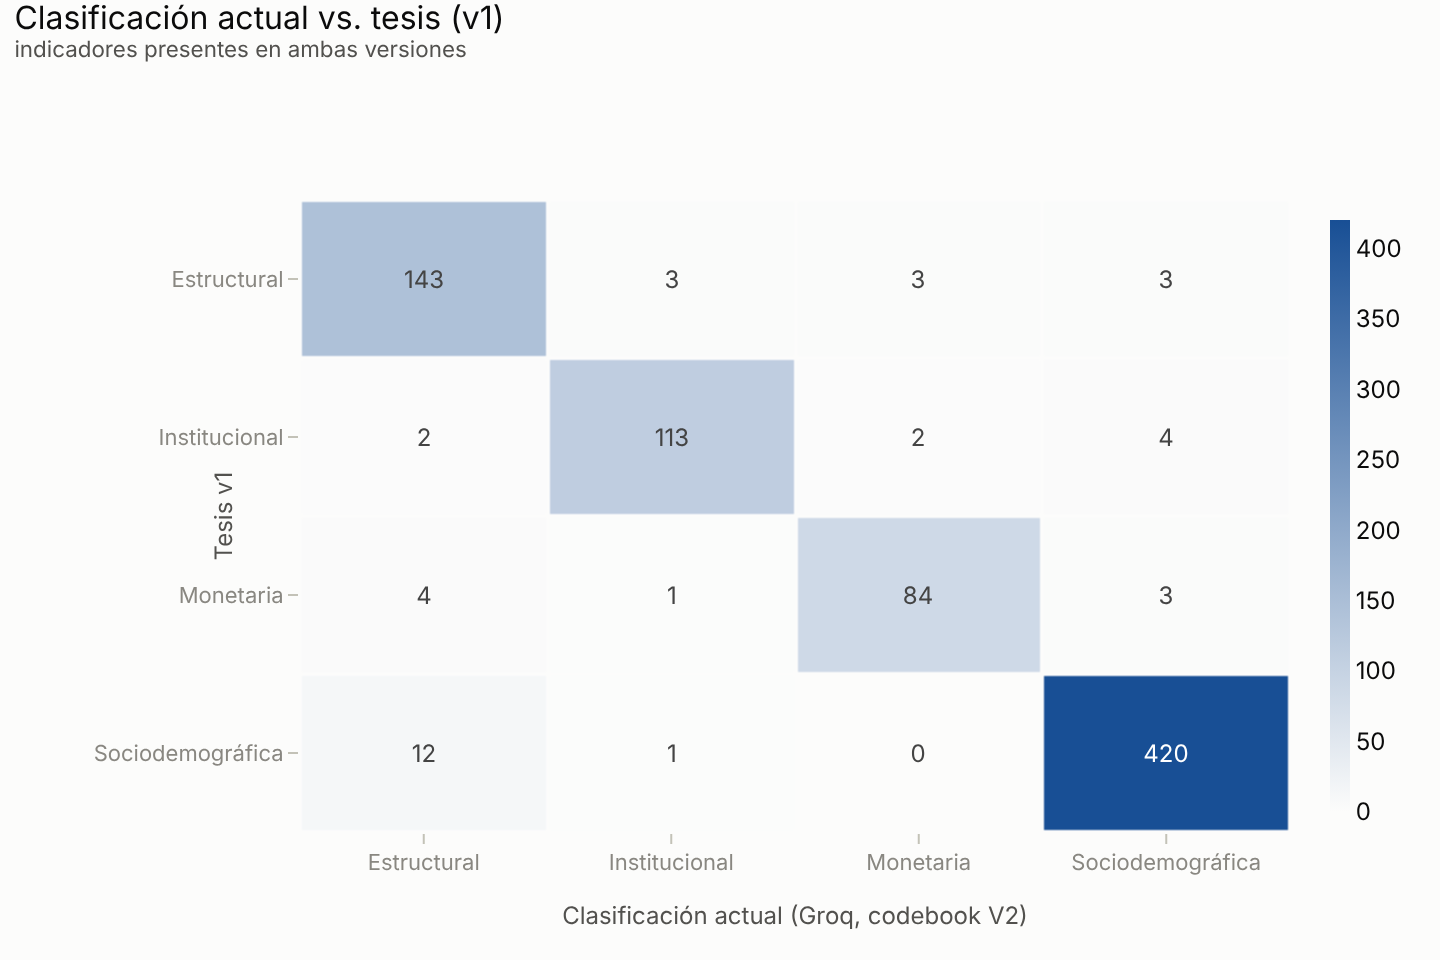

In [9]:
ref = pd.read_csv(Paths.raw / "referencia_tesis" / "clasificacion_tesis_v1.csv").set_index("codigo")["dimension_principal"]
j = final.set_index("codigo").join(ref.rename("dim_tesis"), how="inner")
j = j[j["incluir"]]
cross = pd.crosstab(j["dim_tesis"].map(DIM_LABELS), j["dimension"].map(DIM_LABELS))
print(f"Indicadores comunes incluidos: {len(j)} · misma dimensión: {(j['dimension'] == j['dim_tesis']).mean():.1%}")
fig = heatmap(cross, subtitle("Clasificación actual vs. tesis (v1)", "indicadores presentes en ambas versiones"),
              colorscale=[[0, "#fcfcfb"], [1, SEQUENTIAL_BLUE[5]]], fmt="d")
fig.update_layout(xaxis_title="Clasificación actual (Groq, codebook V2)", yaxis_title="Tesis v1")
show(fig, "02_comparacion_tesis", width=720, height=480)

**Interpretación.** De los 798 indicadores presentes en ambas versiones, el **95,2%** cae en la misma dimensión que en la tesis original, aun con otro procedimiento de preselección (Groq en lugar del agente de relevancia) y dos corridas independientes. Las discrepancias se concentran en las fronteras que el codebook ya identificaba como difíciles: monetaria-estructural (flujos externos, aranceles) y sociodemográfica-estructural (empleo). La clasificación teórica es robusta al procedimiento.

**Limitación.** El LLM resuelve cada indicador por separado, lo que puede producir inconsistencias dentro de una misma familia (por ejemplo, algunas tasas arancelarias quedan en monetaria y otras en estructural). En esos casos se respetó la salida del modelo cuando las dos corridas coincidían, para no introducir decisiones manuales sin un criterio sistemático.